# Sri Lanka Grade 5 Scholarship Examination Performance Analysis - 2026

This project analyzes the performance of candidates in the Sri Lankan Grade 5 Scholarship Examination using official data published by the Department of Examinations, Sri Lanka.


In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
district_df = pd.read_csv("../Data/district_performance_2026.csv")

district_df.head()

,District,Candidates_Sat,Above_Cutoff_No,Above_Cutoff_Pct,Score_Above_100_No,Score_Above_100_Pct,Score_Above_70_No,Score_Above_70_Pct
0,Colombo,23279,3761,16.16,7200,30.93,17059,73.28
1,Gampaha,24200,4674,19.31,8182,33.81,18237,75.36
2,Kalutara,15906,2808,17.65,4947,31.10,11535,72.52
3,Kandy,19570,3025,15.46,5908,30.19,14624,74.73
4,Matale,7835,1317,16.81,2452,31.30,5759,73.50


In [3]:
district_df.shape

(25, 8)

In [4]:
district_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   District             25 non-null     str    
 1   Candidates_Sat       25 non-null     int64  
 2   Above_Cutoff_No      25 non-null     int64  
 3   Above_Cutoff_Pct     25 non-null     float64
 4   Score_Above_100_No   25 non-null     int64  
 5   Score_Above_100_Pct  25 non-null     float64
 6   Score_Above_70_No    25 non-null     int64  
 7   Score_Above_70_Pct   25 non-null     float64
dtypes: float64(3), int64(4), str(1)
memory usage: 1.7 KB


In [5]:
district_df.isnull().sum()

District               0
Candidates_Sat         0
Above_Cutoff_No        0
Above_Cutoff_Pct       0
Score_Above_100_No     0
Score_Above_100_Pct    0
Score_Above_70_No      0
Score_Above_70_Pct     0
dtype: int64

In [6]:
district_df.duplicated().sum()

np.int64(0)

In [7]:
district_df.describe()

,Candidates_Sat,Above_Cutoff_No,Above_Cutoff_Pct,Score_Above_100_No,Score_Above_100_Pct,Score_Above_70_No,Score_Above_70_Pct
count,25.000000,25.000000,25.000000,25.00000,25.000000,25.000000,25.000000
mean,11594.680000,2240.000000,18.303600,3639.56000,29.253600,8531.480000,71.973600
std,6642.391818,1451.990616,4.482255,2439.20959,6.223893,5139.342842,4.797127
min,1562.000000,193.000000,10.380000,324.00000,17.810000,1051.000000,59.440000
25%,7202.000000,1317.000000,15.150000,2104.00000,24.230000,5069.000000,68.180000
50%,11217.000000,2053.000000,17.650000,3288.00000,30.190000,8542.000000,72.890000
75%,15291.000000,3004.000000,20.900000,4947.00000,33.170000,11023.000000,75.360000
max,24407.000000,5963.000000,27.530000,9567.00000,39.200000,19458.000000,79.720000


## Exploratory Data Analysis

In [8]:
district_df.sort_values(
    by="Score_Above_70_Pct",
    ascending=False
)[["District","Score_Above_70_Pct"]]

,District,Score_Above_70_Pct
17,Kurunegala,79.72
24,Kegalle,79.02
8,Hambantota,78.28
23,Ratnapura,76.22
7,Matara,75.90
21,Badulla,75.58
1,Gampaha,75.36
3,Kandy,74.73
22,Monaragala,73.89
4,Matale,73.50


In [9]:
highest = district_df["Score_Above_70_Pct"].max()
lowest = district_df["Score_Above_70_Pct"].min()

gap = highest - lowest

gap

np.float64(20.28)

### Top 5 Districts by Percentage Scoring 70 or Above

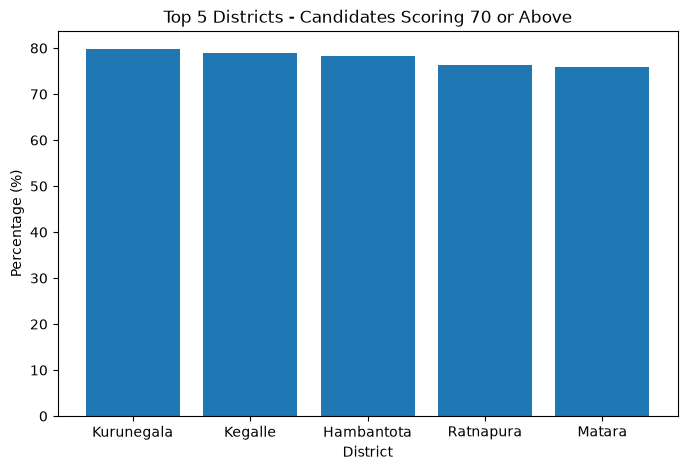

In [10]:
top5 = district_df.nlargest(5, "Score_Above_70_Pct")

plt.figure(figsize=(8, 5))
plt.bar(top5["District"], top5["Score_Above_70_Pct"])

plt.title("Top 5 Districts - Candidates Scoring 70 or Above")
plt.xlabel("District")
plt.ylabel("Percentage (%)")

plt.show()

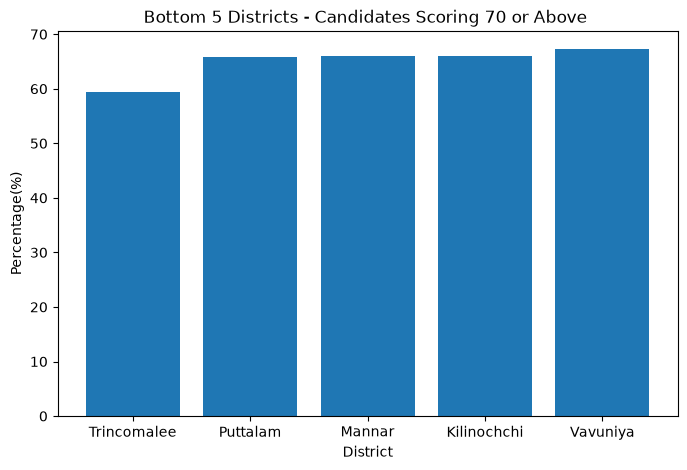

In [12]:
bottom5=district_df.nsmallest(5,"Score_Above_70_Pct")

plt.figure(figsize=(8,5))
plt.bar(bottom5["District"],bottom5["Score_Above_70_Pct"])

plt.title("Bottom 5 Districts - Candidates Scoring 70 or Above ")
plt.xlabel("District")
plt.ylabel("Percentage(%)")

plt.show()

### Top 5 Districts by Percentage Scoring cutoff or above

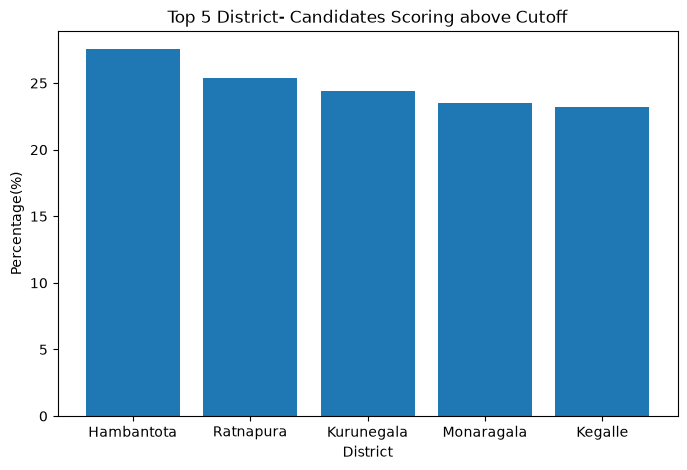

In [16]:
top5=district_df.nlargest(5,"Above_Cutoff_Pct")

plt.figure(figsize=(8,5))
plt.bar(top5["District"],top5["Above_Cutoff_Pct"])

plt.title("Top 5 District- Candidates Scoring above Cutoff")
plt.ylabel("Percentage(%)")
plt.xlabel("District")

plt.show()

### Botttom 5 Districts by Percentage Scoring cutoff or above

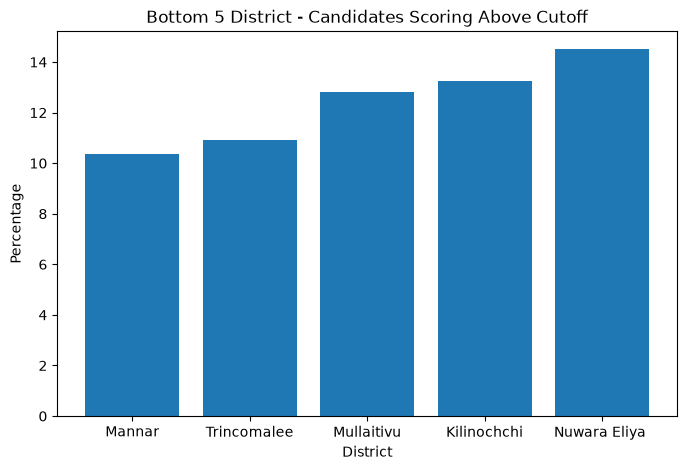

In [18]:
bottom5=district_df.nsmallest(5,"Above_Cutoff_Pct")

plt.figure(figsize=(8,5))
plt.bar(bottom5["District"],bottom5["Above_Cutoff_Pct"])

plt.title("Bottom 5 District - Candidates Scoring Above Cutoff")
plt.ylabel("Percentage")
plt.xlabel("District")

plt.show()


In [22]:
highest=district_df["Above_Cutoff_Pct"].max()
lowest=district_df["Above_Cutoff_Pct"].min()

gap=highest-lowest

gap

np.float64(17.15)

### All the Districts Scoring Above the Cutoff in Descending order (Highest to Lowest)

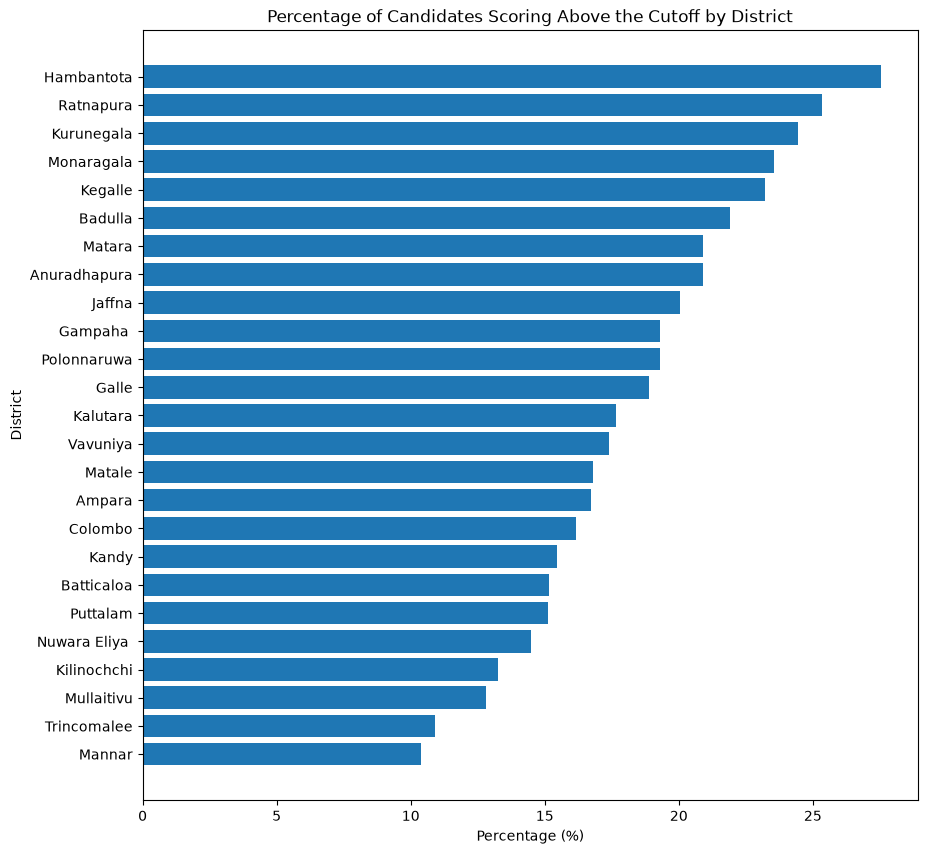

In [25]:
cutoff_sorted = district_df.sort_values(
    by="Above_Cutoff_Pct",
    ascending=False
)

plt.figure(figsize=(10, 10))

plt.barh(
    cutoff_sorted["District"],
    cutoff_sorted["Above_Cutoff_Pct"]
)

plt.title("Percentage of Candidates Scoring Above the Cutoff by District")
plt.xlabel("Percentage (%)")
plt.ylabel("District")

plt.gca().invert_yaxis()

plt.show()

###  Scoring 70 or Above in Descending order (Highest to Lowest)All the Districts

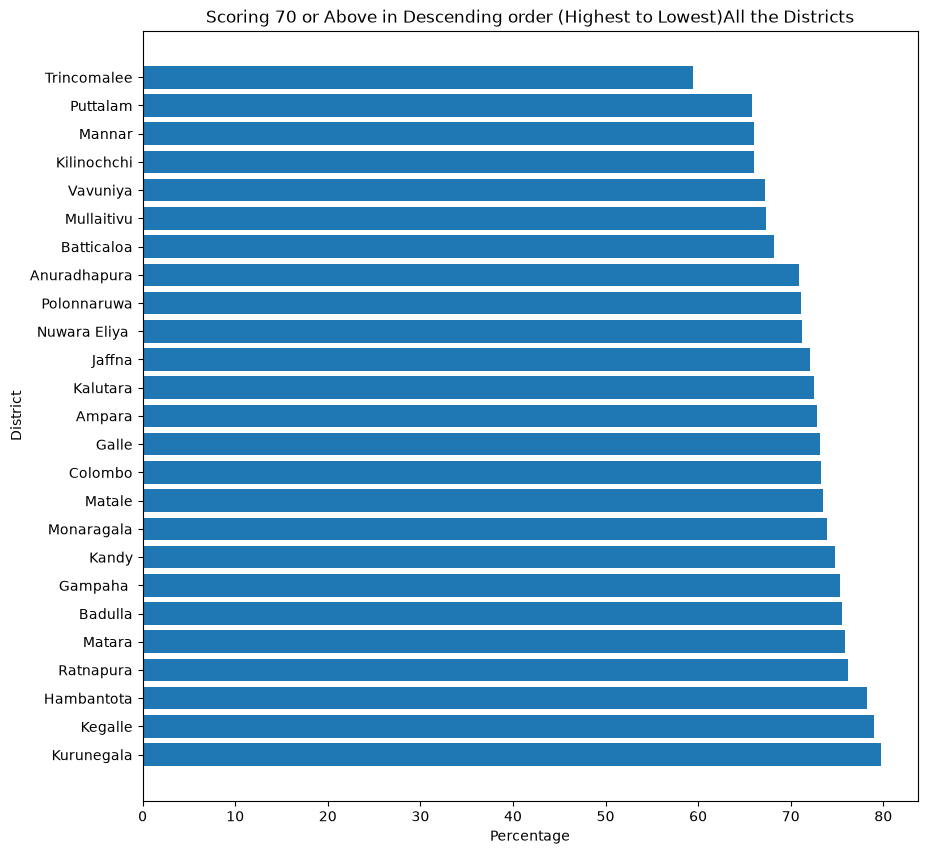

In [28]:
Above_70=district_df.sort_values(
    by="Score_Above_70_Pct",
    ascending=False
)

plt.figure(figsize=(10,10))
plt.barh(
    Above_70["District"],
    Above_70["Score_Above_70_Pct"]
)

plt.title("Scoring 70 or Above in Descending order (Highest to Lowest)All the Districts")
plt.ylabel("District")
plt.xlabel("Percentage")

plt.show()

###  Scoring 100 or Above in Descending order (Highest to Lowest)All the Districts

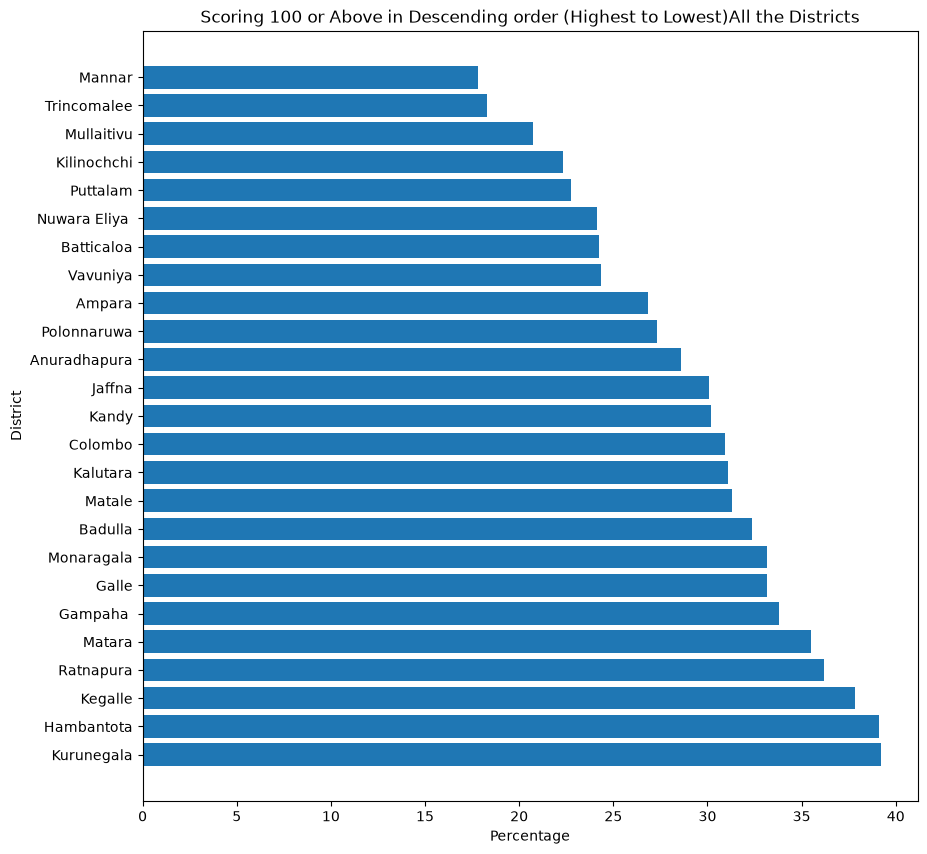

In [29]:
Above_100=district_df.sort_values(
    by="Score_Above_100_Pct",
    ascending=False
)

plt.figure(figsize=(10,10))
plt.barh(
    Above_100["District"],
    Above_100["Score_Above_100_Pct"]
)

plt.title("Scoring 100 or Above in Descending order (Highest to Lowest)All the Districts")
plt.ylabel("District")
plt.xlabel("Percentage")

plt.show()

## National Performance Trends: 2021–2026

In [30]:
national_df = pd.read_csv("../Data/national_performance_2021_2026.csv")

national_df.head(6)

,Year,Candidates_Sat,Above_Cutoff_No,Above_Cutoff_Pct,Score_Above_100_No,Score_Above_100_Pct,Score_Above_70_No,Score_Above_70_Pct,Mean_Marks,Std_Dev_Marks
0,2021,335158,47536,14.18,161202,48.10,258481,77.12,109.31,34.75
1,2022,329668,48257,14.64,157624,47.81,273515,82.97,115.11,32.17
2,2023,332949,50664,15.22,150017,45.06,258871,77.75,111.74,34.98
3,2024,319284,51244,16.05,120370,37.70,248912,77.96,107.25,30.88
4,2025,303671,51969,17.11,98417,32.41,213872,70.43,102.44,32.54
5,2026,289867,56000,19.32,90989,31.39,213287,73.58,106.48,30.66


In [31]:
national_df.shape

(6, 10)

In [32]:
national_df.describe

<bound method NDFrame.describe of    Year  Candidates_Sat  Above_Cutoff_No  Above_Cutoff_Pct  \
0  2021          335158            47536             14.18   
1  2022          329668            48257             14.64   
2  2023          332949            50664             15.22   
3  2024          319284            51244             16.05   
4  2025          303671            51969             17.11   
5  2026          289867            56000             19.32   

   Score_Above_100_No  Score_Above_100_Pct  Score_Above_70_No  \
0              161202                48.10             258481   
1              157624                47.81             273515   
2              150017                45.06             258871   
3              120370                37.70             248912   
4               98417                32.41             213872   
5               90989                31.39             213287   

   Score_Above_70_Pct  Mean_Marks  Std_Dev_Marks  
0               77.12   

In [33]:
national_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 6 non-null      int64  
 1   Candidates_Sat       6 non-null      int64  
 2   Above_Cutoff_No      6 non-null      int64  
 3   Above_Cutoff_Pct     6 non-null      float64
 4   Score_Above_100_No   6 non-null      int64  
 5   Score_Above_100_Pct  6 non-null      float64
 6   Score_Above_70_No    6 non-null      int64  
 7   Score_Above_70_Pct   6 non-null      float64
 8   Mean_Marks           6 non-null      float64
 9   Std_Dev_Marks        6 non-null      float64
dtypes: float64(5), int64(5)
memory usage: 612.0 bytes


In [34]:
national_df.isnull().sum()

Year                   0
Candidates_Sat         0
Above_Cutoff_No        0
Above_Cutoff_Pct       0
Score_Above_100_No     0
Score_Above_100_Pct    0
Score_Above_70_No      0
Score_Above_70_Pct     0
Mean_Marks             0
Std_Dev_Marks          0
dtype: int64

In [35]:
national_df.duplicated().sum()

np.int64(0)

### Trend of Candidates Scoring 70 or Above

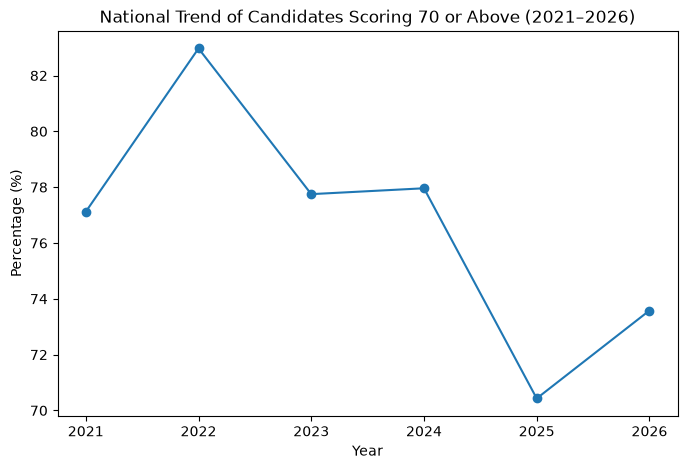

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    national_df["Year"],
    national_df["Score_Above_70_Pct"],
    marker="o"
)

plt.title("National Trend of Candidates Scoring 70 or Above (2021–2026)")
plt.xlabel("Year")
plt.ylabel("Percentage (%)")

plt.show()

In [37]:
national_df.loc[national_df["Score_Above_70_Pct"].idxmax(), ["Year", "Score_Above_70_Pct"]]

Year                  2022.00
Score_Above_70_Pct      82.97
Name: 1, dtype: float64

In [38]:
national_df.loc[national_df["Score_Above_70_Pct"].idxmin(), ["Year", "Score_Above_70_Pct"]]

Year                  2025.00
Score_Above_70_Pct      70.43
Name: 4, dtype: float64

In [39]:
change_2025_2026 = 73.58 - 70.43
change_2025_2026

3.1499999999999915

### Trend of Candidates Scoring 100 or Above

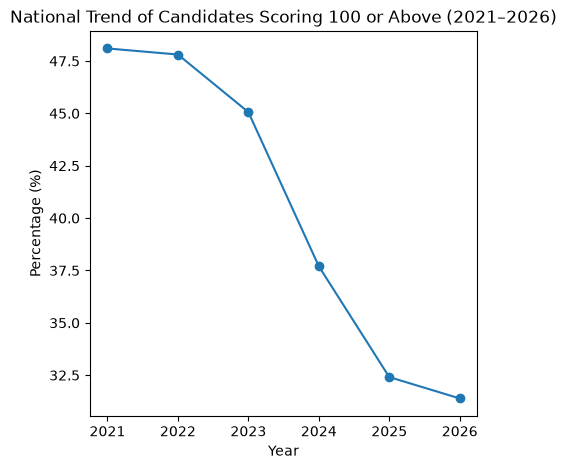

In [41]:
plt.figure(figsize=(5, 5))

plt.plot(
    national_df["Year"],
    national_df["Score_Above_100_Pct"],
    marker="o"
)

plt.title("National Trend of Candidates Scoring 100 or Above (2021–2026)")
plt.xlabel("Year")
plt.ylabel("Percentage (%)")

plt.show()

In [42]:
decline_100 = 48.10 - 31.39
decline_100

16.71

### Trend of Candidates Scoring On or Above the Cutoff

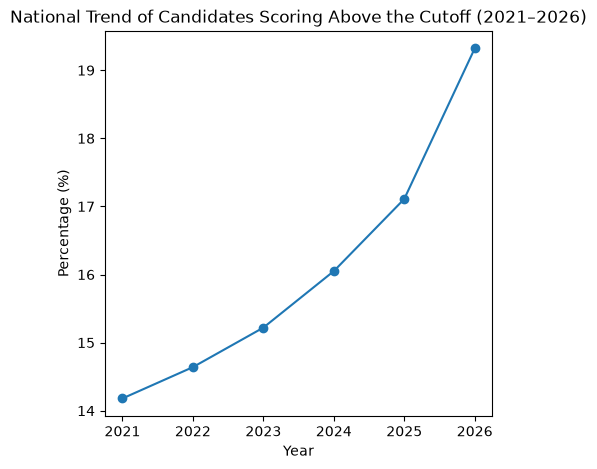

In [43]:
plt.figure(figsize=(5, 5))

plt.plot(
    national_df["Year"],
    national_df["Above_Cutoff_Pct"],
    marker="o"
)

plt.title("National Trend of Candidates Scoring Above the Cutoff (2021–2026)")
plt.xlabel("Year")
plt.ylabel("Percentage (%)")

plt.show()

In [44]:
increase_cutoff = 19.32 - 14.18
increase_cutoff

5.140000000000001

### Trend of Mean Marks

In [45]:
national_df["Mean_Marks"]

0    109.31
1    115.11
2    111.74
3    107.25
4    102.44
5    106.48
Name: Mean_Marks, dtype: float64

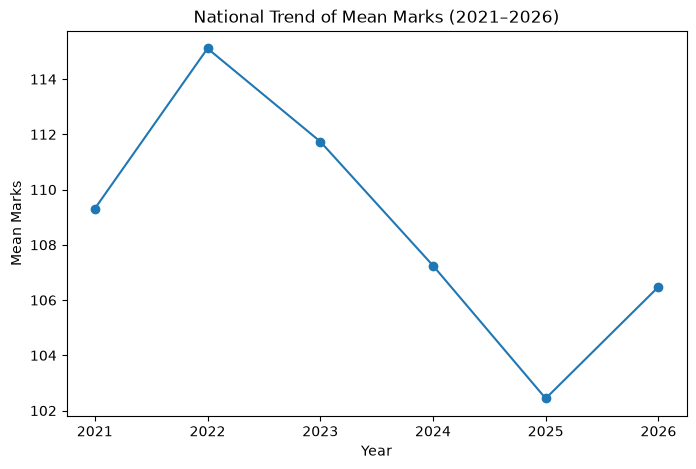

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    national_df["Year"],
    national_df["Mean_Marks"],
    marker="o"
)

plt.title("National Trend of Mean Marks (2021–2026)")
plt.xlabel("Year")
plt.ylabel("Mean Marks")

plt.show()

### Trend in Number of Candidates

In [47]:
national_df["Candidates_Sat"]

0    335158
1    329668
2    332949
3    319284
4    303671
5    289867
Name: Candidates_Sat, dtype: int64

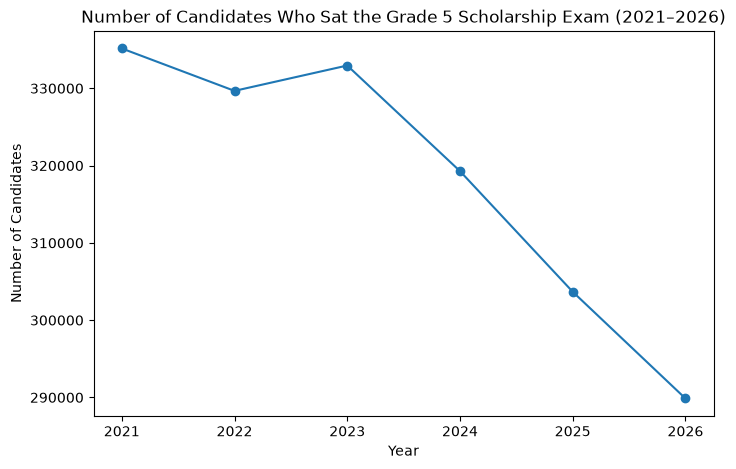

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(
    national_df["Year"],
    national_df["Candidates_Sat"],
    marker="o"
)

plt.title("Number of Candidates Who Sat the Grade 5 Scholarship Exam (2021–2026)")
plt.xlabel("Year")
plt.ylabel("Number of Candidates")

plt.show()

## Basic Household Infrastructure Analysis - 2024

In [50]:
infra_df = pd.read_csv("../Data/district_basic_infrastructure_2024.csv")

infra_df.head()

,District,Number_Of_Households,Grid_Electricity_No,Grid_Electricity_Pct,Pipe_Borne_Water_No,Pipe_Borne_Water_Pct,Exclusive_Toilet_No,Exclusive_Toilet_Pct
0,Colombo,661822,653239,98.70,573126,86.60,634188,95.82
1,Gampaha,688635,680337,98.80,301032,43.71,639917,92.93
2,Kalutara,352963,348801,98.82,168229,47.66,334975,94.90
3,Kandy,397626,392207,98.64,288598,72.58,369807,93.00
4,Matale,151132,148488,98.25,87372,57.81,136036,90.01


In [52]:
infra_df.shape

(25, 8)

In [53]:
infra_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   District              25 non-null     str    
 1   Number_Of_Households  25 non-null     int64  
 2   Grid_Electricity_No   25 non-null     int64  
 3   Grid_Electricity_Pct  25 non-null     float64
 4   Pipe_Borne_Water_No   25 non-null     int64  
 5   Pipe_Borne_Water_Pct  25 non-null     float64
 6   Exclusive_Toilet_No   25 non-null     int64  
 7   Exclusive_Toilet_Pct  25 non-null     float64
dtypes: float64(3), int64(4), str(1)
memory usage: 1.7 KB


In [54]:
infra_df.isnull().sum()

District                0
Number_Of_Households    0
Grid_Electricity_No     0
Grid_Electricity_Pct    0
Pipe_Borne_Water_No     0
Pipe_Borne_Water_Pct    0
Exclusive_Toilet_No     0
Exclusive_Toilet_Pct    0
dtype: int64

In [55]:
infra_df.duplicated().sum()

np.int64(0)

In [57]:
district_df = pd.read_csv("../Data/district_performance_2026.csv")

district_df.head()

,District,Candidates_Sat,Above_Cutoff_No,Above_Cutoff_Pct,Score_Above_100_No,Score_Above_100_Pct,Score_Above_70_No,Score_Above_70_Pct
0,Colombo,23279,3761,16.16,7200,30.93,17059,73.28
1,Gampaha,24200,4674,19.31,8182,33.81,18237,75.36
2,Kalutara,15906,2808,17.65,4947,31.10,11535,72.52
3,Kandy,19570,3025,15.46,5908,30.19,14624,74.73
4,Matale,7835,1317,16.81,2452,31.30,5759,73.50


In [58]:
set(district_df["District"]) - set(infra_df["District"])

{'Ratnapura'}

In [59]:
set(infra_df["District"]) - set(district_df["District"])

{'Rathnapura'}

In [60]:
infra_df["District"] = infra_df["District"].replace("Rathnapura", "Ratnapura")

In [61]:
set(district_df["District"]) - set(infra_df["District"])

set()

In [62]:
set(infra_df["District"]) - set(district_df["District"])

set()

## Relationship Between Basic Household Infrastructure and Grade 5 Scholarship Performance


In [63]:
combined_df = pd.merge(
    district_df,
    infra_df,
    on="District",
    how="inner"
)

combined_df.head()

,District,Candidates_Sat,Above_Cutoff_No,Above_Cutoff_Pct,Score_Above_100_No,Score_Above_100_Pct,Score_Above_70_No,Score_Above_70_Pct,Number_Of_Households,Grid_Electricity_No,Grid_Electricity_Pct,Pipe_Borne_Water_No,Pipe_Borne_Water_Pct,Exclusive_Toilet_No,Exclusive_Toilet_Pct
0,Colombo,23279,3761,16.16,7200,30.93,17059,73.28,661822,653239,98.70,573126,86.60,634188,95.82
1,Gampaha,24200,4674,19.31,8182,33.81,18237,75.36,688635,680337,98.80,301032,43.71,639917,92.93
2,Kalutara,15906,2808,17.65,4947,31.10,11535,72.52,352963,348801,98.82,168229,47.66,334975,94.90
3,Kandy,19570,3025,15.46,5908,30.19,14624,74.73,397626,392207,98.64,288598,72.58,369807,93.00
4,Matale,7835,1317,16.81,2452,31.30,5759,73.50,151132,148488,98.25,87372,57.81,136036,90.01


In [64]:
combined_df.shape

(25, 15)

In [65]:
combined_df.columns

Index(['District', 'Candidates_Sat', 'Above_Cutoff_No', 'Above_Cutoff_Pct',
       'Score_Above_100_No', 'Score_Above_100_Pct', 'Score_Above_70_No',
       'Score_Above_70_Pct', 'Number_Of_Households', 'Grid_Electricity_No',
       'Grid_Electricity_Pct', 'Pipe_Borne_Water_No', 'Pipe_Borne_Water_Pct',
       'Exclusive_Toilet_No', 'Exclusive_Toilet_Pct'],
      dtype='str')

### Grid Electricity and Grade 5 Scholarship Performance

#### Grid Electricity vs Candidates Scoring 70 or Above

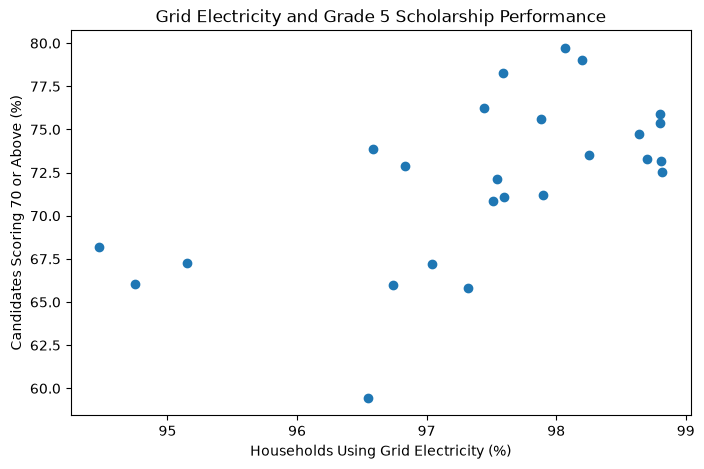

In [66]:
plt.figure(figsize=(8, 5))

plt.scatter(
    combined_df["Grid_Electricity_Pct"],
    combined_df["Score_Above_70_Pct"]
)

plt.title("Grid Electricity and Grade 5 Scholarship Performance")
plt.xlabel("Households Using Grid Electricity (%)")
plt.ylabel("Candidates Scoring 70 or Above (%)")

plt.show()

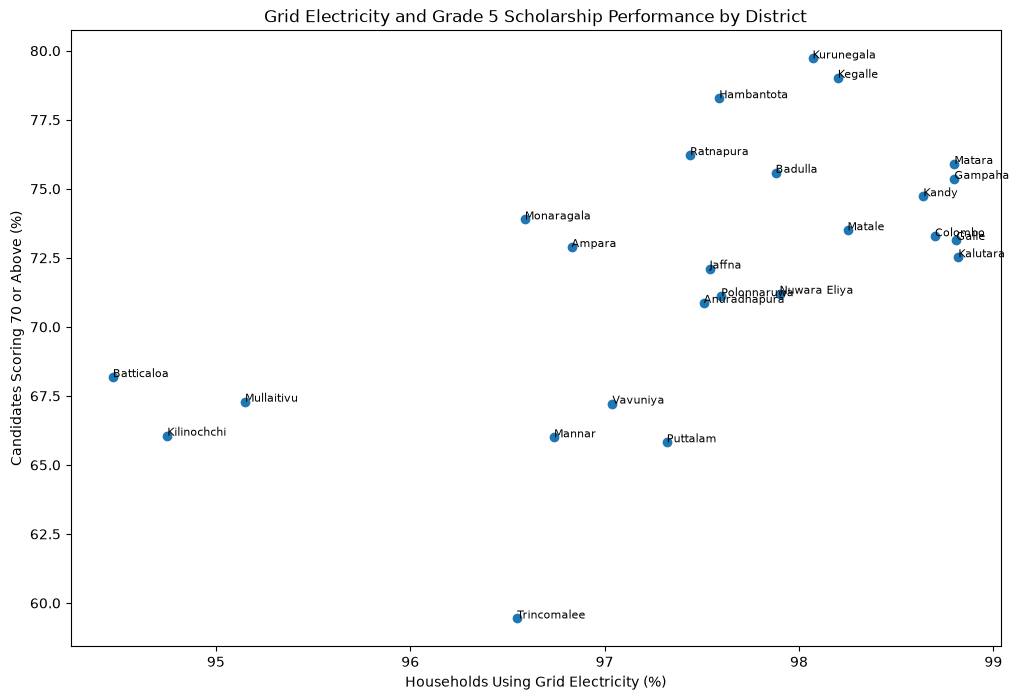

In [67]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Grid_Electricity_Pct"],
    combined_df["Score_Above_70_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Grid_Electricity_Pct"], row["Score_Above_70_Pct"]),
        fontsize=8
    )

plt.title("Grid Electricity and Grade 5 Scholarship Performance by District")
plt.xlabel("Households Using Grid Electricity (%)")
plt.ylabel("Candidates Scoring 70 or Above (%)")

plt.show()

#### Correlation Between Grid Electricity and Candidates Scoring 70 or Above

In [68]:
electricity_corr = combined_df[
    "Grid_Electricity_Pct"
].corr(
    combined_df["Score_Above_70_Pct"]
)

electricity_corr

np.float64(0.5947766472449612)

#### Grid Electricity vs Candidates Scoring 100 or Above

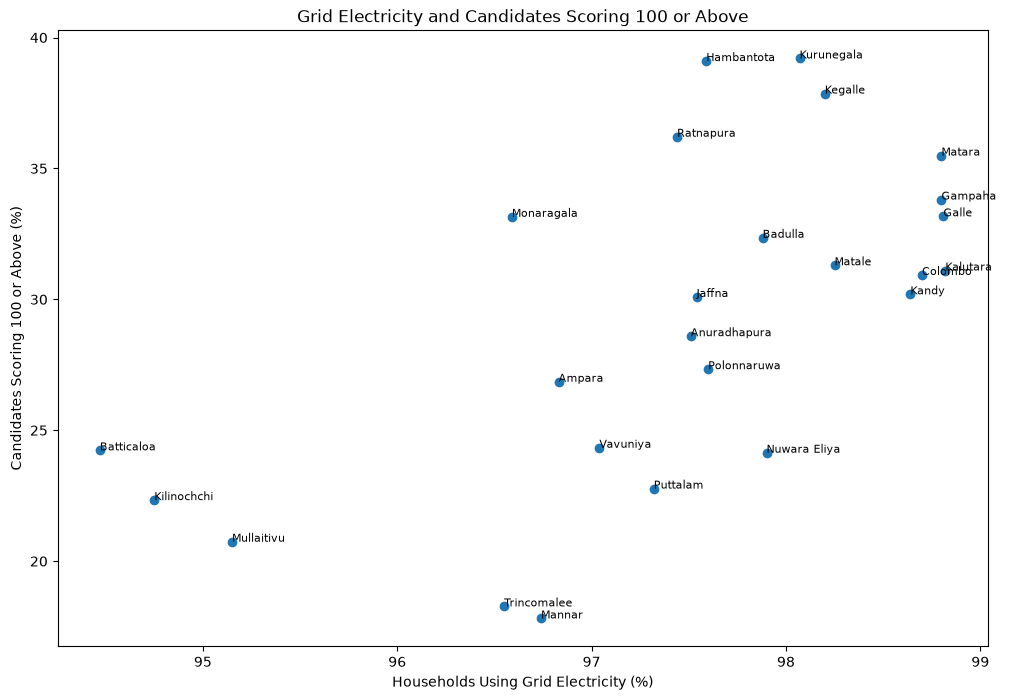

In [69]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Grid_Electricity_Pct"],
    combined_df["Score_Above_100_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Grid_Electricity_Pct"], row["Score_Above_100_Pct"]),
        fontsize=8
    )

plt.title("Grid Electricity and Candidates Scoring 100 or Above")
plt.xlabel("Households Using Grid Electricity (%)")
plt.ylabel("Candidates Scoring 100 or Above (%)")

plt.show()

#### Correlation Between Grid Electricity and Candidates Scoring 100 or Above

In [70]:
electricity_100_corr = combined_df[
    "Grid_Electricity_Pct"
].corr(
    combined_df["Score_Above_100_Pct"]
)

electricity_100_corr

np.float64(0.609629885168612)

#### Grid Electricity vs Candidates Reaching the Scholarship Cutoff

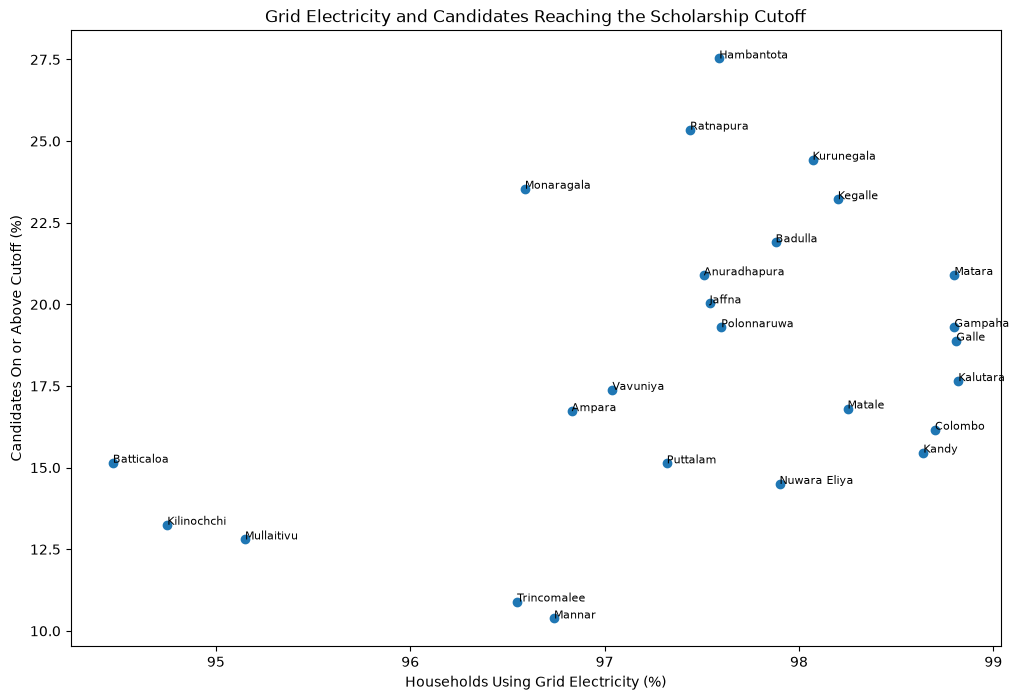

In [71]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Grid_Electricity_Pct"],
    combined_df["Above_Cutoff_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Grid_Electricity_Pct"], row["Above_Cutoff_Pct"]),
        fontsize=8
    )

plt.title("Grid Electricity and Candidates Reaching the Scholarship Cutoff")
plt.xlabel("Households Using Grid Electricity (%)")
plt.ylabel("Candidates On or Above Cutoff (%)")

plt.show()

#### Correlation Between Grid Electricity and Candidates Reaching the Scholarship Cutoff

In [72]:
electricity_cutoff_corr = combined_df[
    "Grid_Electricity_Pct"
].corr(
    combined_df["Above_Cutoff_Pct"]
)

electricity_cutoff_corr

np.float64(0.3904013249022489)

**Interpretation:**  
Grid electricity usage shows a moderate positive correlation with the percentage of candidates scoring 70 or above (r = 0.59), a strong positive correlation with the percentage scoring 100 or above (r = 0.61), and a weak positive correlation with the percentage reaching the scholarship cutoff (r = 0.39).

Overall, districts with higher grid electricity usage tended to show better Grade 5 Scholarship performance, particularly for candidates scoring 100 or above. However, these correlations show association only and do not prove that electricity access causes better examination performance.


### Pipe Borne Water and Grade 5 Scholarship Performance

#### Pipe-Borne Water vs Candidates Scoring 70 or Above

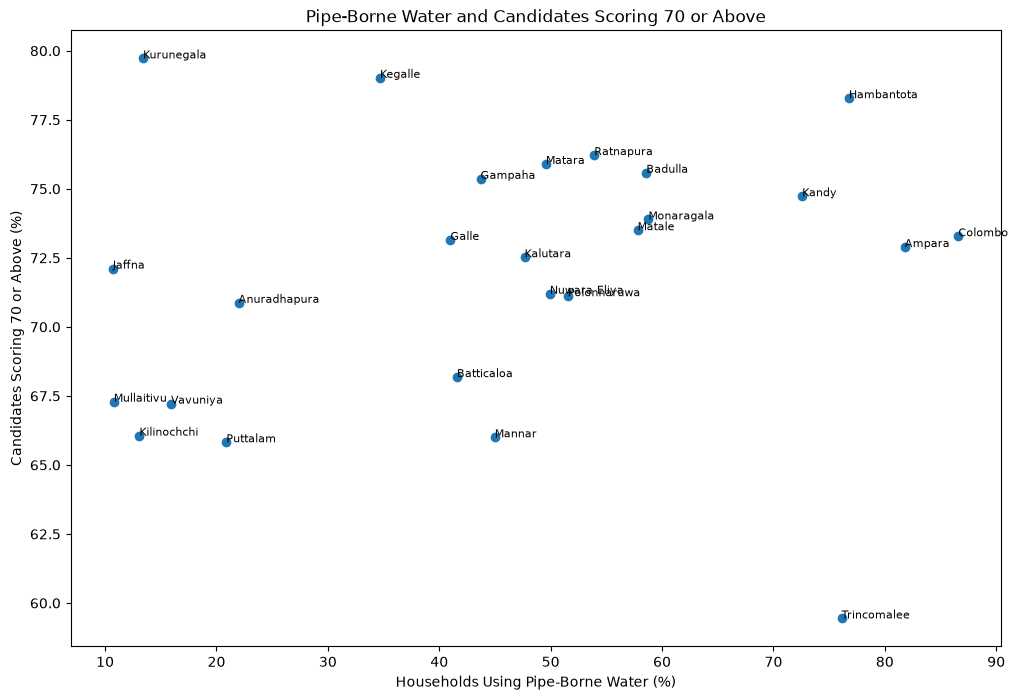

In [73]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Pipe_Borne_Water_Pct"],
    combined_df["Score_Above_70_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Pipe_Borne_Water_Pct"], row["Score_Above_70_Pct"]),
        fontsize=8
    )

plt.title("Pipe-Borne Water and Candidates Scoring 70 or Above")
plt.xlabel("Households Using Pipe-Borne Water (%)")
plt.ylabel("Candidates Scoring 70 or Above (%)")

plt.show()

#### Correlation Between Pipe Borne Water and Candidates Reaching Score 70 or Above

In [74]:
water_70_corr = combined_df[
    "Pipe_Borne_Water_Pct"
].corr(
    combined_df["Score_Above_70_Pct"]
)

water_70_corr

np.float64(0.1717747887264781)

#### Pipe-Borne Water vs Candidates Scoring 100 or Above

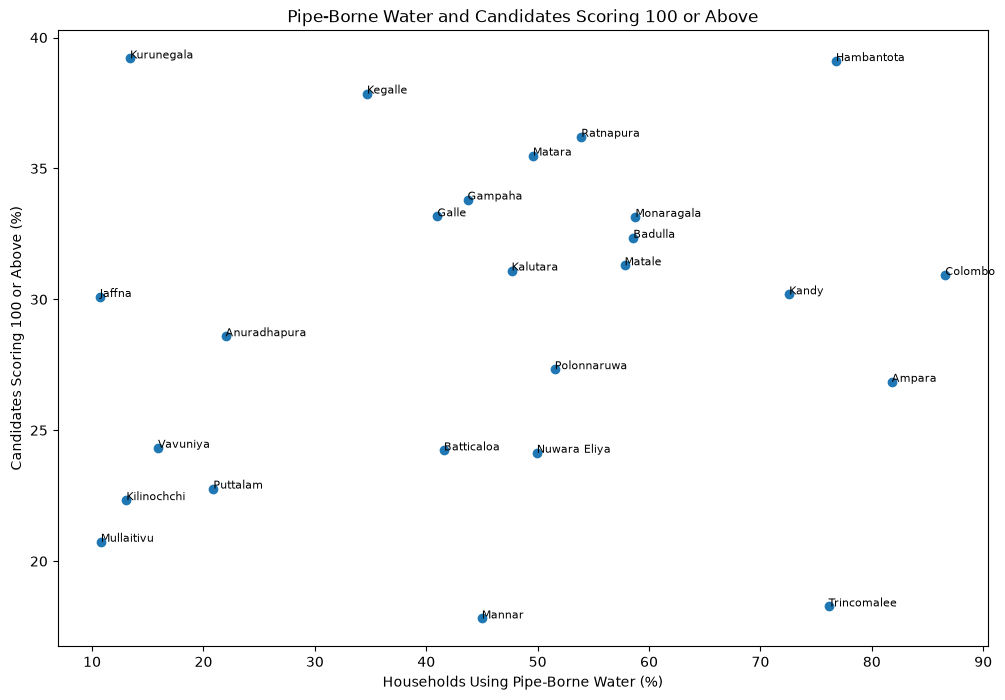

In [75]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Pipe_Borne_Water_Pct"],
    combined_df["Score_Above_100_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Pipe_Borne_Water_Pct"], row["Score_Above_100_Pct"]),
        fontsize=8
    )

plt.title("Pipe-Borne Water and Candidates Scoring 100 or Above")
plt.xlabel("Households Using Pipe-Borne Water (%)")
plt.ylabel("Candidates Scoring 100 or Above (%)")

plt.show()

#### Correlation Between Pipe-Borne Water and Candidates Scoring 100 or Above

In [76]:
water_100_corr = combined_df[
    "Pipe_Borne_Water_Pct"
].corr(
    combined_df["Score_Above_100_Pct"]
)

water_100_corr

np.float64(0.15797810368920276)

#### Pipe-Borne Water vs Candidates Reaching the Scholarship Cutoff

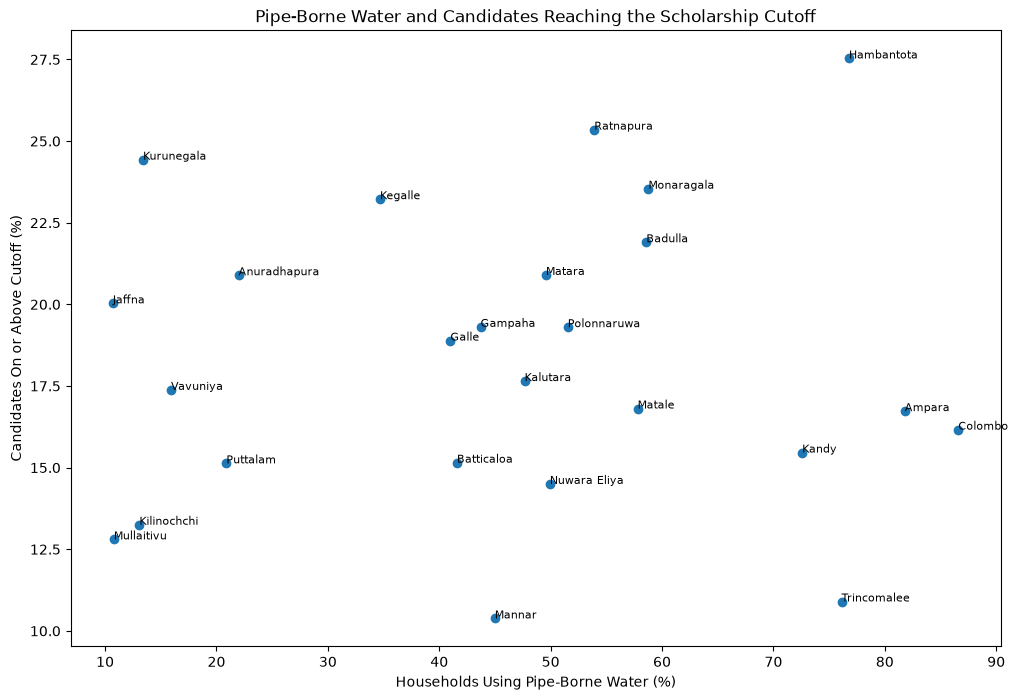

In [77]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Pipe_Borne_Water_Pct"],
    combined_df["Above_Cutoff_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Pipe_Borne_Water_Pct"], row["Above_Cutoff_Pct"]),
        fontsize=8
    )

plt.title("Pipe-Borne Water and Candidates Reaching the Scholarship Cutoff")
plt.xlabel("Households Using Pipe-Borne Water (%)")
plt.ylabel("Candidates On or Above Cutoff (%)")

plt.show()

#### Correlation Between Pipe-Borne Water and Candidates Reaching the Scholarship Cutoff

In [78]:
water_cutoff_corr = combined_df[
    "Pipe_Borne_Water_Pct"
].corr(
    combined_df["Above_Cutoff_Pct"]
)

water_cutoff_corr

np.float64(0.03880759885350887)

**Interpretation:**  
Pipe-borne water usage shows only very weak positive correlations with Grade 5 Scholarship performance. The correlation is r = 0.17 for candidates scoring 70 or above, r = 0.16 for candidates scoring 100 or above, and r = 0.04 for candidates reaching the scholarship cutoff.

These results suggest that district-level pipe-borne water usage has little to no clear linear association with Grade 5 Scholarship performance in this dataset.

### Exclusive Toilet Facilities and Grade 5 Scholarship Performance

#### Exclusive Toilet Facilities vs Candidates Scoring 70 or Above

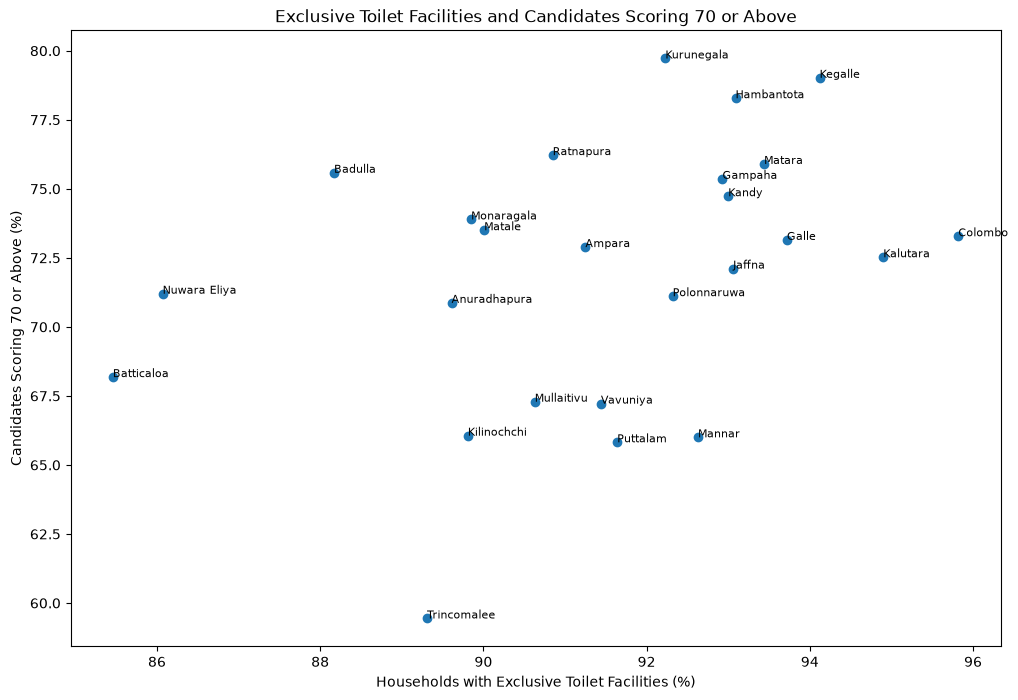

In [79]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Exclusive_Toilet_Pct"],
    combined_df["Score_Above_70_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Exclusive_Toilet_Pct"], row["Score_Above_70_Pct"]),
        fontsize=8
    )

plt.title("Exclusive Toilet Facilities and Candidates Scoring 70 or Above")
plt.xlabel("Households with Exclusive Toilet Facilities (%)")
plt.ylabel("Candidates Scoring 70 or Above (%)")

plt.show()

#### Correlation Between Exclusive Toilet Facilities and Candidates Scoring 70 or Above

In [80]:
toilet_70_corr = combined_df[
    "Exclusive_Toilet_Pct"
].corr(
    combined_df["Score_Above_70_Pct"]
)

toilet_70_corr

np.float64(0.3567746163895854)

#### Exclusive Toilet Facilities vs Candidates Scoring 100 or Above

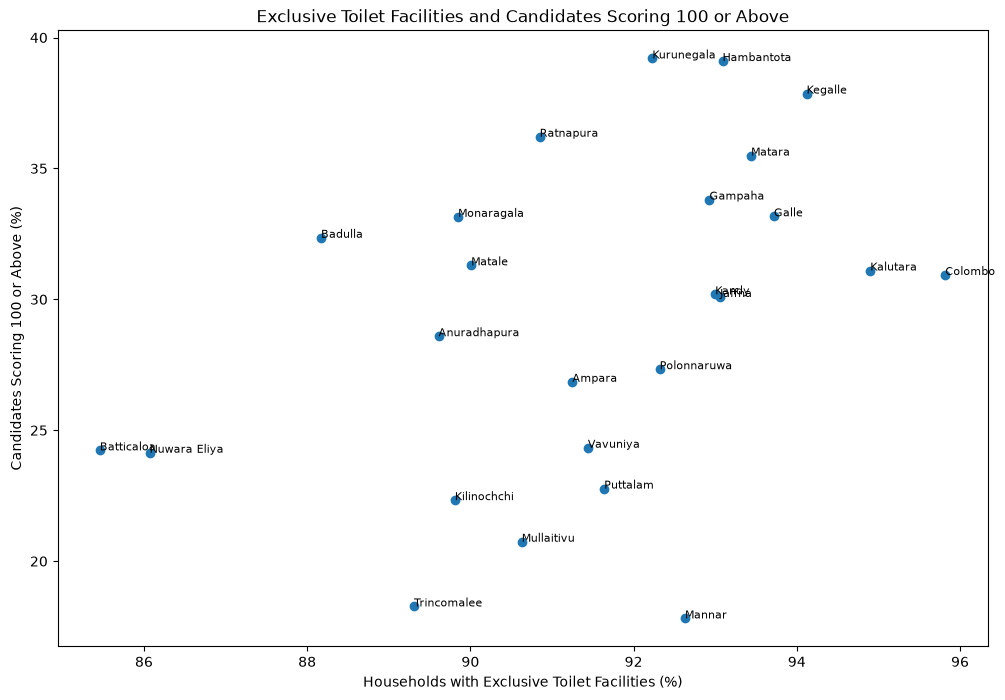

In [81]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Exclusive_Toilet_Pct"],
    combined_df["Score_Above_100_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Exclusive_Toilet_Pct"], row["Score_Above_100_Pct"]),
        fontsize=8
    )

plt.title("Exclusive Toilet Facilities and Candidates Scoring 100 or Above")
plt.xlabel("Households with Exclusive Toilet Facilities (%)")
plt.ylabel("Candidates Scoring 100 or Above (%)")

plt.show()

#### Correlation Between Exclusive Toilet Facilities and Candidates Scoring 100 or Above

In [82]:
toilet_100_corr = combined_df[
    "Exclusive_Toilet_Pct"
].corr(
    combined_df["Score_Above_100_Pct"]
)

toilet_100_corr

np.float64(0.40644139586821043)

#### Exclusive Toilet Facilities vs Candidates Reaching the Scholarship Cutoff

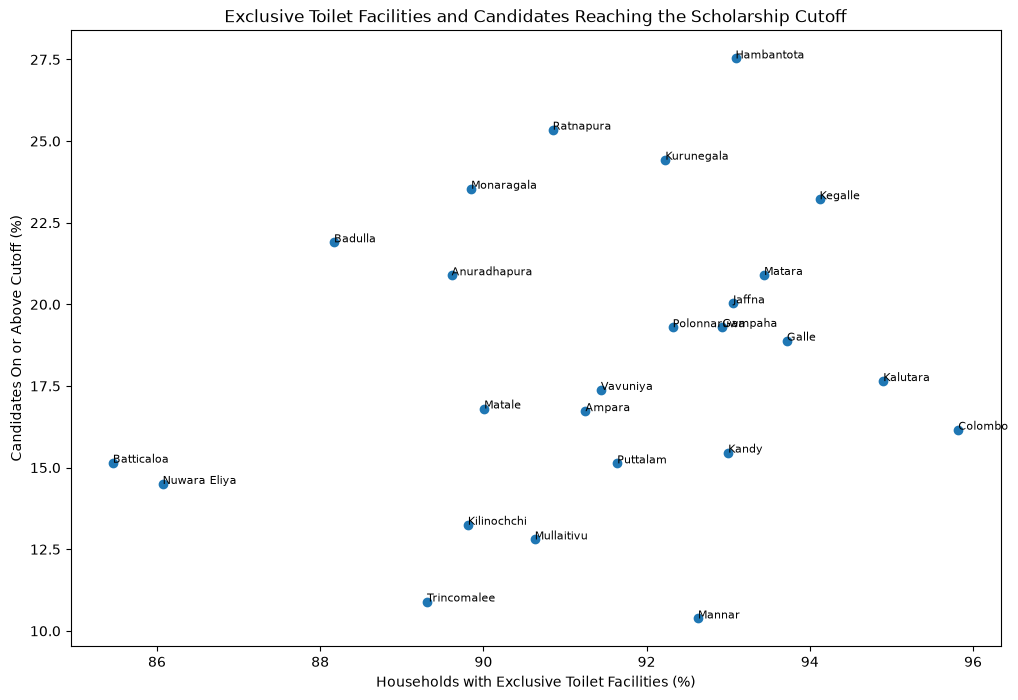

In [83]:
plt.figure(figsize=(12, 8))

plt.scatter(
    combined_df["Exclusive_Toilet_Pct"],
    combined_df["Above_Cutoff_Pct"]
)

for i, row in combined_df.iterrows():
    plt.annotate(
        row["District"],
        (row["Exclusive_Toilet_Pct"], row["Above_Cutoff_Pct"]),
        fontsize=8
    )

plt.title("Exclusive Toilet Facilities and Candidates Reaching the Scholarship Cutoff")
plt.xlabel("Households with Exclusive Toilet Facilities (%)")
plt.ylabel("Candidates On or Above Cutoff (%)")

plt.show()

#### Correlation Between Exclusive Toilet Facilities and Candidates Reaching the Scholarship Cutoff

In [84]:
toilet_cutoff_corr = combined_df[
    "Exclusive_Toilet_Pct"
].corr(
    combined_df["Above_Cutoff_Pct"]
)

toilet_cutoff_corr

np.float64(0.2217560720130542)

**Interpretation:**  
Exclusive toilet facilities show a weak positive correlation with the percentage of candidates scoring 70 or above (r = 0.36), a moderate positive correlation with the percentage scoring 100 or above (r = 0.41), and a weak positive correlation with the percentage reaching the scholarship cutoff (r = 0.22).

Overall, districts with higher percentages of households having exclusive toilet facilities tended to show slightly better Grade 5 Scholarship performance. However, the relationships are not strong, and these results indicate association rather than causation.

### Summary of Infrastructure and Scholarship Performance Correlations

In [85]:
correlation_summary = pd.DataFrame({
    "Infrastructure Indicator": [
        "Grid Electricity",
        "Pipe-Borne Water",
        "Exclusive Toilet Facilities"
    ],
    "Score 70+ Correlation": [
        electricity_corr,
        water_70_corr,
        toilet_70_corr
    ],
    "Score 100+ Correlation": [
        electricity_100_corr,
        water_100_corr,
        toilet_100_corr
    ],
    "Above Cutoff Correlation": [
        electricity_cutoff_corr,
        water_cutoff_corr,
        toilet_cutoff_corr
    ]
})

correlation_summary

,Infrastructure Indicator,Score 70+ Correlation,Score 100+ Correlation,Above Cutoff Correlation
0,Grid Electricity,0.594777,0.609630,0.390401
1,Pipe-Borne Water,0.171775,0.157978,0.038808
2,Exclusive Toilet Facilities,0.356775,0.406441,0.221756


In [86]:
correlation_summary.round(2)

,Infrastructure Indicator,Score 70+ Correlation,Score 100+ Correlation,Above Cutoff Correlation
0,Grid Electricity,0.59,0.61,0.39
1,Pipe-Borne Water,0.17,0.16,0.04
2,Exclusive Toilet Facilities,0.36,0.41,0.22


### Correlation Heatmap of Infrastructure and Scholarship Performance

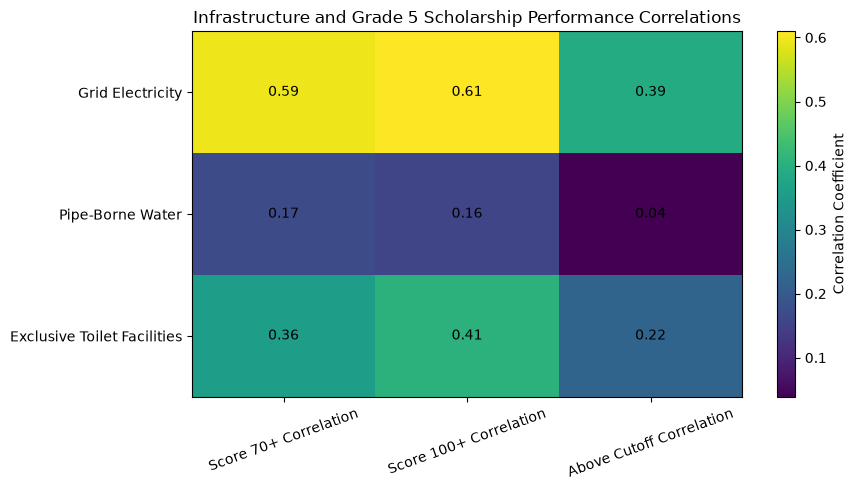

In [87]:
heatmap_data = correlation_summary.set_index("Infrastructure Indicator")

plt.figure(figsize=(9, 5))

plt.imshow(heatmap_data, aspect="auto")

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns,
    rotation=20
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        plt.text(
            j,
            i,
            f"{heatmap_data.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(label="Correlation Coefficient")
plt.title("Infrastructure and Grade 5 Scholarship Performance Correlations")
plt.tight_layout()
plt.show()

## Limitations

- The educational performance data are from the 2026 Grade 5 Scholarship Examination, while the household infrastructure data are from the 2024 Census. Therefore, the datasets do not represent exactly the same year.
- The analysis is based on district-level aggregated data. It does not represent the circumstances of individual students or households.
- Correlation does not prove causation. A relationship between infrastructure and educational performance does not mean that infrastructure directly causes higher or lower examination results.
- Only three household infrastructure indicators were considered: grid electricity, pipe-borne water and exclusive toilet facilities.
- Educational outcomes may also be associated with many other factors such as household income, parental education, school resources, teaching quality, access to tuition and learning materials.
- Grade 5 Scholarship Examination performance was used as one measurable indicator of educational achievement and should not be considered a complete representation of the overall education system.

## Final Conclusion

This analysis suggests that basic household infrastructure has a small to moderate association with educational performance at the district level. Grade 5 Scholarship Examination performance was used in this project as a measurable indicator of educational achievement in order to examine this relationship.

Among the infrastructure factors considered, grid electricity showed the strongest positive relationship with educational performance, while exclusive toilet facilities showed weaker positive relationships. Pipe-borne water showed very little relationship with the selected educational performance indicators.

Overall, the findings suggest that household living conditions may be one of many factors associated with educational outcomes. However, infrastructure alone cannot explain differences in educational performance. Other factors such as family income, quality of teaching, school resources, parental support, access to learning materials and individual student characteristics may also play important roles.

Therefore, these results should be interpreted as evidence of association rather than causation. The Grade 5 Scholarship Examination was used only as an available indicator of educational performance, and the findings should not be generalized to the entire education system without further research.

## Resources

### Data Sources

- [Department of Examinations, Sri Lanka – Statistics](https://www.doenets.lk/statistics)
  - Grade 5 Scholarship Examination Performance Statistics, 2026.

- [Department of Examinations – Official Examination Results](https://www.results.exams.gov.lk/home.htm)
  - Grade 5 Scholarship Examination Results.

- [Department of Census and Statistics, Sri Lanka – Census of Population and Housing 2024](https://www.statistics.gov.lk/Population/StaticalInformation/CPH2024/)
  - Households by main source of drinking water at district level, 2024.
  - Households by source of lighting at district level, 2024.
  - Households using toilet facilities at district level, 2024.

### Tools and Libraries

- Microsoft Excel – Data preparation and percentage calculations.
- Python – Data analysis.
- Pandas – Data cleaning, merging and statistical analysis.
- NumPy – Numerical operations.
- Matplotlib – Data visualization.
- Jupyter Notebook – Analysis and documentation.
- Visual Studio Code – Project development environment.